# Data Cleaning & Set Up

In [54]:

import pandas as pd
import sqlite3



In [55]:
conn = sqlite3.connect('loveisblind.db')
%load_ext sql
%sql sqlite:///loveisblind.db



The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [56]:
#create table for contestants
df = pd.read_csv('contestants.csv')
contestants_table = df.to_sql('contestants', conn, if_exists='replace', index=False)
#create table for relationships
df = pd.read_csv('relationships.csv')
relationships_table = df.to_sql('relationships', conn, if_exists='replace', index=False)


In [57]:
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

In [58]:
%%sql
SELECT * FROM contestants LIMIT 2;


 * sqlite:///loveisblind.db
Done.


contestant_id,name,season,age,gender,occupation,city,has_children 0=no
C001,Alyson Costa,1,36,F,Pediatric Nurse Client Relations Director,Atlanta,0
C002,Amber Pike,1,27,F,Ex-Tank Mechanic,Atlanta,0


## Data Cleaning for Contestant Data

In [59]:
%%sql
--I'm trimming and normalizeing the names, gender, city, 
--and occupation to lowercase. 
UPDATE contestants 
SET name = TRIM(LOWER(name)),
 gender = TRIM(lower(gender)),
 city = TRIM(lower(city)),
 occupation = TRIM(lower(occupation));
--show results
SELECT * from contestants LIMIT 5;


 * sqlite:///loveisblind.db
300 rows affected.
Done.


contestant_id,name,season,age,gender,occupation,city,has_children 0=no
C001,alyson costa,1,36,f,pediatric nurse client relations director,atlanta,0
C002,amber pike,1,27,f,ex-tank mechanic,atlanta,0
C003,andy rickert,1,30,m,welder,atlanta,0
C004,briana holmes,1,24,f,ceo,atlanta,0
C005,cameron hamilton,1,28,m,data scientist,atlanta,0


In [60]:
%%sql
SELECT * FROM relationships LIMIT 2;

 * sqlite:///loveisblind.db
Done.


relationship_id,female_id,male_id,made_it_to_the_alter,sex_during_honeymoon,season,age_difference,married,love_triange,engaged,together_after_1_year
1,C002,C024,Y,Y,1,0,Y,Y,Y,Y
2,C020,C005,Y,Y,1,4,Y,N,Y,Y


## Analyze Data Using SQL

### Question 1: Who is the youngest Contestant?

In [61]:
%%sql
SELECT  name, season ,MIN(age) AS youngest_contestant_age
FROM contestants;


 * sqlite:///loveisblind.db
Done.


name,season,youngest_contestant_age
briana holmes,1,24


In [62]:
%%sql
SELECT  
        season, 
        MIN(age) AS youngest_contestant_age
FROM contestants
GROUP BY season
ORDER BY youngest_contestant_age ASC;


 * sqlite:///loveisblind.db
Done.


season,youngest_contestant_age
1,24
5,24
6,24
3,25
4,26
7,26
8,26
2,27
9,27
10,28


### Question 2: Who is the oldest contestant?

In [63]:
%%sql
SELECT  name,season, MAX(age) AS oldest_contestant_age
FROM contestants;

 * sqlite:///loveisblind.db
Done.


name,season,oldest_contestant_age
amanda burke,8,43


In [64]:
%%sql
SELECT  
        season, 
        MAX(age) AS oldest_contestant_age
FROM contestants
GROUP BY season
ORDER BY oldest_contestant_age ASC;

 * sqlite:///loveisblind.db
Done.


season,oldest_contestant_age
5,34
3,36
6,36
7,37
1,38
2,39
4,39
10,39
9,41
8,43


### Question 3: What is the average age of ALL contestants?

In [65]:
%%sql

SELECT AVG(age) as average_age_of_all_contestants
FROM contestants;

 * sqlite:///loveisblind.db
Done.


average_age_of_all_contestants
31.116666666666667


### Question 4: What is the average age of contestants by season?

In [66]:
%%sql
--
SELECT season, round(AVG(age), 0) as average_age
FROM contestants
GROUP BY season
ORDER BY average_age DESC;


 * sqlite:///loveisblind.db
Done.


season,average_age
10,33.0
9,32.0
7,32.0
8,31.0
4,31.0
3,31.0
2,31.0
6,30.0
5,30.0
1,30.0


What we can gather from this data is that for the most part average age increased as the show went on. Earlier we saw the youngest age did increase as the seasons went on. Oldest Contestant increased as the seasons went by. 

### Question 5: How many contestants are in each season?

In [67]:
%%sql 
SELECT SEASON, COUNT(*) AS num_contestants
FROM contestants
GROUP BY season;

 * sqlite:///loveisblind.db
Done.


season,num_contestants
1,29
2,29
3,30
4,30
5,28
6,29
7,29
8,32
9,32
10,32


## Taking a look at Relationships Table
I wanted to do this join to see all the couples from the show and the final outcome of their relationship. This is to help with creating and understanding questions I'm going to ask about the relationship Table

In [68]:
%%sql 

SELECT 
    r.relationship_id, female.name as feamle_name, 
    male.name as male_name,engaged,  married

FROM relationships r
JOIN contestants female 
ON r.female_id = female.contestant_id
JOIN contestants male
ON r.male_id = male.contestant_id;

 * sqlite:///loveisblind.db
Done.


relationship_id,feamle_name,male_name,engaged,married
1,amber pike,matthew barnett,Y,Y
2,lauren speed,cameron hamilton,Y,Y
3,diamond jack,carlton morton,Y,N
4,giannina gibelli,damian powers,Y,N
5,danielle drouin,rory newbrough,Y,N
6,carlton morton,mark cuevas,Y,N
7,kelly chase,kenny barnes,Y,N
8,lexie skipper,westley baer,Y,N
9,deepti vempati,abhishek chatterjee,Y,N
10,caitlin mckee,james miller,Y,N


### Question 7: What percentage of contestants got engaged?

In [69]:
%%sql
SELECT COUNT(*) AS 
total_contestants
FROM contestants;



 * sqlite:///loveisblind.db
Done.


total_contestants
300


In [70]:
%%sql
SELECT COUNT(*) AS 
engaged_contestants
FROM (
    SELECT female_id as contestant_id
    FROM relationships

    UNION
    SELECT male_id as contestant_id
    FROM relationships
) AS gotEngaged;



 * sqlite:///loveisblind.db
Done.


engaged_contestants
124


In [71]:
#percentage of contestants that got engaged: 
percentageOfEngagement = (124/300) * 100
print(round(percentageOfEngagement,2))

41.33


### Question 8: What Season has the most Engagements

In [72]:
%%sql
SELECT season, COUNT(*) as Num_of_Engagements
FROM relationships
GROUP BY season
ORDER BY num_of_engagements DESC

 * sqlite:///loveisblind.db
Done.


season,Num_of_Engagements
4,9
2,8
1,8
10,7
7,7
9,6
8,5
6,5
3,5
5,4


In [73]:
%%sql
--showing average number of engagements. 
SELECT 
COUNT(*) / 10 as average_numOf_engagements
FROM relationships

 * sqlite:///loveisblind.db
Done.


average_numOf_engagements
6


Based on these results there was something about Season 4 that had engagements up. Engagments were very low for season 5. It would be smart to look at different things about these 2 seasons to see what might cause a huge increase in enegagments. 

### Question 9: What Percentage of engagements resulted in marriage

In [74]:
%%sql
--SELECT COUNT(*) as numEngagements
--FROM relationships
--SELECT COUNT(*) as numMarried
--FROM relationships
--WHERE married = 'Y';

--Realized after more learning that this can be put into one query.
SELECT
    COUNT(*) as numEngagments, 
    SUM(CASE WHEN married = 'Y' THEN 1 ELSE 0 END) AS numMarried, 
    SUM(CASE WHEN married = 'Y' THEN 1 ELSE 0 END)* 100.0 / COUNT(*) as percentageMarried

FROM relationships


 * sqlite:///loveisblind.db
Done.


numEngagments,numMarried,percentageMarried
64,16,25.0


I want to see this now by season. The percentage of marriages is pretty low. Only 25% got married.

### Question 10: What is the percentage of engaged couples that got Married for each season?

In [75]:
%%sql
SELECT
    season,
    COUNT(*) as numEngagments, 
    SUM(CASE WHEN married = 'Y' THEN 1 ELSE 0 END) AS numMarried, 
    round(SUM(CASE WHEN married = 'Y' THEN 1 ELSE 0 END)* 100.0 / COUNT(*), 2)as percentageMarried

FROM relationships
GROUP BY season
ORDER BY percentageMarried DESC

 * sqlite:///loveisblind.db
Done.


season,numEngagments,numMarried,percentageMarried
3,5,2,40.0
4,9,3,33.33
10,7,2,28.57
7,7,2,28.57
5,4,1,25.0
2,8,2,25.0
1,8,2,25.0
8,5,1,20.0
6,5,1,20.0
9,6,0,0.0


Season 3 was one of the lowest number of Engagements but had the highest percentage of marriages out off the seasons. Where season 4 had a high number of engagements and a high percentage of people married. 

Season 9 was a historic season where none of the engaged couples got married.

In my next section of Analysis I want to take a look at Season 9, 3, 4, and 5

# Exploratory Data Analysis 
I'm currently watching through the [Data 100 course at UC Berkley](https://ds100.org/fa26/). During the lectures on EDA I & EDA II we've gone through these steps: 
1. View a preview of a dataframe
2. Select specific col.
3. Create new col. 
4. Filter to specific rows
5. Order the data by val in a col. 
6. Calculate summary of stat for one or more col
7. Visualize 1D data w/ blox plot or histogram
8. Visualize 2D data w/ scatterplot or lineplot
9. Group by some variable, and then do something. 

I'm going to go through my dataset using these steps

In [76]:
import polars as pl
import seaborn as sns


## 1.View a preview of a dataframe

In [77]:
contestants_df = pl.read_csv("contestants.csv")
relationships_df = pl.read_csv("relationships.csv")


contestants_df

contestant_id,name,season,age,gender,occupation,city,has_children 0=no
str,str,i64,i64,str,str,str,i64
"""C001""","""Alyson Costa""",1,36,"""F""","""Pediatric Nurse Client Relatio…","""Atlanta""",0
"""C002""","""Amber Pike""",1,27,"""F""","""Ex-Tank Mechanic""","""Atlanta""",0
"""C003""","""Andy Rickert""",1,30,"""M""","""Welder""","""Atlanta""",0
"""C004""","""Briana Holmes""",1,24,"""F""","""CEO""","""Atlanta""",0
"""C005""","""Cameron Hamilton""",1,28,"""M""","""Data Scientist""","""Atlanta""",0
…,…,…,…,…,…,…,…
"""C296""","""Jennifer Underwood""",10,32,"""F""","""Financial Professional""","""Ohio""",0
"""C297""","""Keya Kellum""",10,31,"""F""","""Marketing Director""","""Ohio""",0
"""C298""","""Priyanka Grandhi""",10,34,"""F""","""Recruiter""","""Ohio""",0


In [78]:
relationships_df

relationship_id,female_id,male_id,made_it_to_the_alter,sex_during_honeymoon,season,age_difference,married,love_triange,engaged,together_after_1_year
i64,str,str,str,str,i64,i64,str,str,str,str
1,"""C002""","""C024""","""Y""","""Y""",1,0,"""Y""","""Y""","""Y""","""Y"""
2,"""C020""","""C005""","""Y""","""Y""",1,4,"""Y""","""N""","""Y""","""Y"""
3,"""C009""","""C006""","""N""","""N""",1,6,"""N""","""N""","""Y""","""N"""
4,"""C011""","""C007""","""Y""","""Y""",1,2,"""N""","""N""","""Y""","""N"""
5,"""C008""","""C026""","""N""",null,1,1,"""N""",null,"""Y""","""N"""
…,…,…,…,…,…,…,…,…,…,…
60,"""C277""","""C278""",null,null,10,3,"""N""",null,"""Y""","""N"""
61,"""C279""","""C281""",null,null,10,2,"""N""",null,"""Y""","""N"""
62,"""C275""","""C276""",null,null,10,1,"""N""",null,"""Y""","""N"""


## 2. Select a specific Col.

After looking at the contestant data I came up with a few questions. I asked Chat GPT for rewording my original question so that it can be more polished for this project. 

>"Is there an association between a contestant's City and their engagement status"

>"Is age associated with the linkelihood of a contestant getting engaged?"

>"Is there an association between a contestant's occupation and thier engagement status?"

I'm looking at Age, City, and Occupation.



## 3. Create New Col

First thing I need to do is to add a col for engagement. I decided for it to be binary 0=did not get engaged 1=got engaged

In [79]:
#getting IDs from relationship.csv of couples
engaged_ids = pl.concat([
    relationships_df.select(
        pl.col("female_id").alias("contestant_id")
    ), 
    relationships_df.select(
        pl.col("male_id").alias("contestant_id")
    )
]).unique()

contestants = contestants_df.join(
    engaged_ids.with_columns(pl.lit(1). alias("engaged")), 
    on="contestant_id", 
    how="left"
).with_columns(
    pl.col("engaged").fill_null(0).cast(pl.Int8)
)

print(contestants.group_by("engaged")
      .len()
      .sort("engaged"))

shape: (2, 2)
┌─────────┬─────┐
│ engaged ┆ len │
│ ---     ┆ --- │
│ i8      ┆ u32 │
╞═════════╪═════╡
│ 0       ┆ 176 │
│ 1       ┆ 124 │
└─────────┴─────┘


## 4. Filter to Specific Rows

>"Is age associated with the likelihood of a contestant getting engaged?"

In [80]:
engaged_contestants = contestants.filter(pl.col('engaged') == 1)

single_contestants = contestants.filter(pl.col('engaged') == 0)




## 5. Order the data by values in a col. 

## 6. Calculate Summary stat for one or more col.

In [81]:
avg_age_engaged_contestants = engaged_contestants.select(pl.mean("age").cast(pl.Int64))
youngest_engaged_contestant = engaged_contestants.select(pl.min("age"))
oldest_engaged_contestant = engaged_contestants.select(pl.max("age"))
median_engaged_contestant = engaged_contestants.select(pl.median("age"))
print("--------------Engaged Contestant Summary--------------------")
print("mean")
print(avg_age_engaged_contestants)
print("youngest contestant")
print(youngest_engaged_contestant)
print("oldest contestant")
print(oldest_engaged_contestant)
print("median")
print(median_engaged_contestant)
avg_age_single_contestants = single_contestants.select(pl.mean('age').cast(pl.Int64))
youngest_single_contestant = single_contestants.select(pl.min("age"))
oldest_single_contestant = single_contestants.select(pl.max("age"))
median_single_contestant = single_contestants.select(pl.median("age"))
print("--------------Single Contestant Summary--------------------")
print("mean")
print(avg_age_single_contestants)
print("youngest contestant")
print(youngest_single_contestant)
print("oldest contestant")
print(oldest_single_contestant)
print("median")
print(median_engaged_contestant)


--------------Engaged Contestant Summary--------------------
mean
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 30  │
└─────┘
youngest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 24  │
└─────┘
oldest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 41  │
└─────┘
median
shape: (1, 1)
┌──────┐
│ age  │
│ ---  │
│ f64  │
╞══════╡
│ 31.0 │
└──────┘
--------------Single Contestant Summary--------------------
mean
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 31  │
└─────┘
youngest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 24  │
└─────┘
oldest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 43  │
└─────┘
median
shape: (1, 1)
┌──────┐
│ age  │
│ ---  │
│ f64  │
╞══════╡
│ 31.0 │
└──────┘


This is interesting. I wasn't expecting the summary statistics to be the same. Let's take a look at some visualization. 

## 7. Visualize 1D data w/ bloxplot or histogram

<Axes: xlabel='age'>

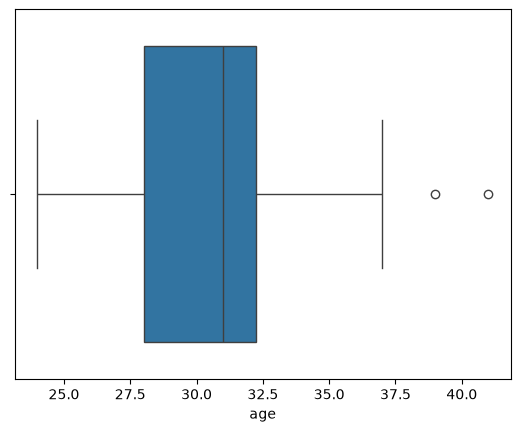

In [82]:
sns.boxplot(engaged_contestants, x="age")

<Axes: xlabel='age'>

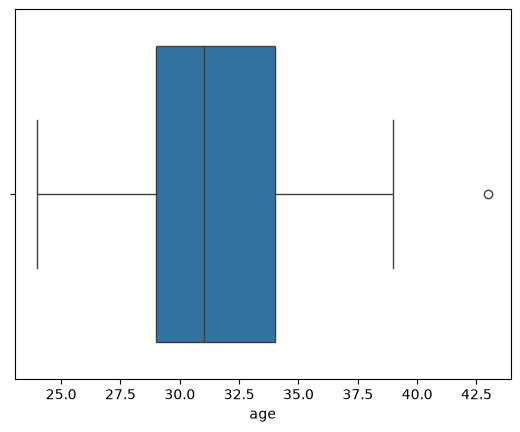

In [83]:
sns.boxplot(single_contestants, x="age")

Boxplots are pretty similiar for engaged contestants ages it ranges from 27.5-32.5 and single contestants 29-34 ages. Based off of these boxplots I would say that contestants who are in the 27.5-32.5 are more likely to get married.

Text(0.5, 1.0, 'Engaged Contestants Ages')

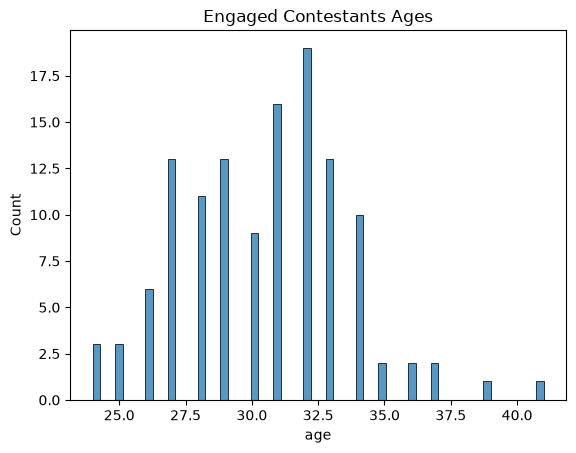

In [84]:
sns.histplot(engaged_contestants, x='age', bins= 60).set_title("Engaged Contestants Ages")

Text(0.5, 1.0, 'Single Contestant Ages')

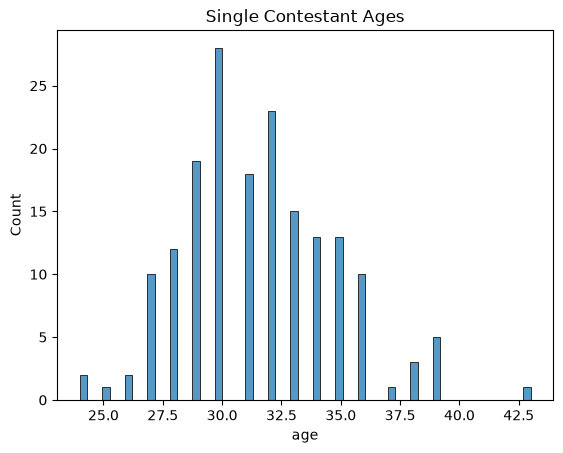

In [85]:
sns.histplot(single_contestants, x='age', bins = 60).set_title("Single Contestant Ages")

I believe the histogram is better at showing us the age range of contestants that are more likely to get engaged on the show. It gives us more information then just the standard statistics and the Box plots. The Engaged histogram being Bi-modal really is interesting. It changes my original thoughts. Now I can see that ages in a certain age are more likely to get engaged. 30 year-olds show a dramatic drop in engagement.

## 7. Visualize 2D data w/ scatterplot or lineplot

<Axes: >

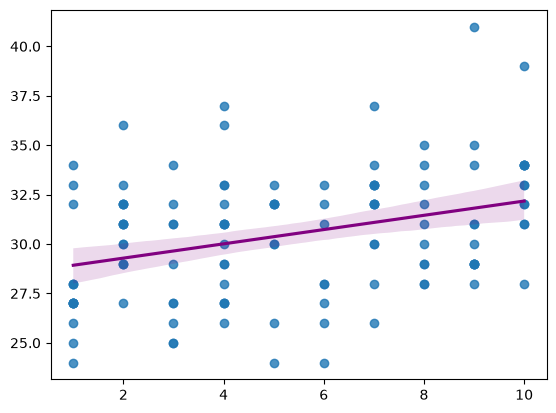

In [86]:
sns.regplot(engaged_contestants,
            x='season',
            y='age', 
            line_kws={"color": "purple"})

## 8.Group By some variable and then do "something"

In [87]:
contestants = contestants.with_columns(
    pl.when(pl.col("age").is_between(24,26))
    .then(pl.lit("24-26"))
    .when(pl.col("age").is_between(27,29))
    .then(pl.lit("27-29"))
    .when(pl.col("age") == 30)
    .then(pl.lit("30"))
    .when(pl.col("age").is_between(31,33))
    .then(pl.lit("31-33"))
    .when(pl.col("age").is_between(34,36))
    .then(pl.lit("34-36"))
    .when(pl.col("age") > 36)
    .then(pl.lit("37+"))
    .otherwise(None)
    .alias("age_group")
    
)
print(contestants.select(["age", "age_group"]).head(10))

shape: (10, 2)
┌─────┬───────────┐
│ age ┆ age_group │
│ --- ┆ ---       │
│ i64 ┆ str       │
╞═════╪═══════════╡
│ 36  ┆ 34-36     │
│ 27  ┆ 27-29     │
│ 30  ┆ 30        │
│ 24  ┆ 24-26     │
│ 28  ┆ 27-29     │
│ 34  ┆ 34-36     │
│ 27  ┆ 27-29     │
│ 27  ┆ 27-29     │
│ 28  ┆ 27-29     │
│ 30  ┆ 30        │
└─────┴───────────┘


I took all the contestants and puts them into ranged groups based on their age. 

<Axes: xlabel='age_group', ylabel='Count'>

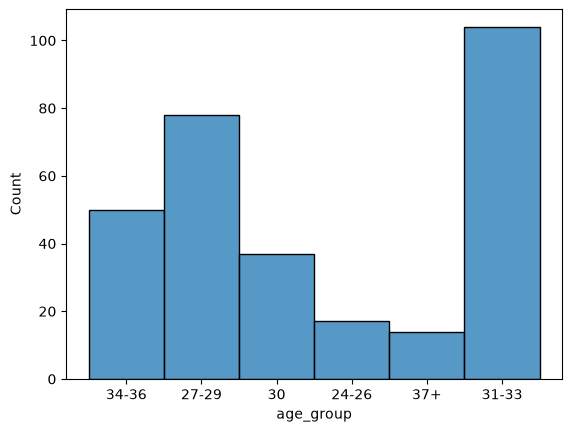

In [88]:
sns.histplot(contestants, x='age_group') 
#take a look back at this the age_groups are not in order

In [89]:
results = (
    contestants.group_by("age_group")
    .agg(
        pl.len().alias("total_contestants"),
        pl.col("engaged").sum().alias("engaged_contestants "), 
        (pl.col("engaged").mean() * 100).alias("engagement_rate")
    )
    .sort("age_group")
)
print(results)

shape: (6, 4)
┌───────────┬───────────────────┬──────────────────────┬─────────────────┐
│ age_group ┆ total_contestants ┆ engaged_contestants  ┆ engagement_rate │
│ ---       ┆ ---               ┆ ---                  ┆ ---             │
│ str       ┆ u32               ┆ i64                  ┆ f64             │
╞═══════════╪═══════════════════╪══════════════════════╪═════════════════╡
│ 24-26     ┆ 17                ┆ 12                   ┆ 70.588235       │
│ 27-29     ┆ 78                ┆ 37                   ┆ 47.435897       │
│ 30        ┆ 37                ┆ 9                    ┆ 24.324324       │
│ 31-33     ┆ 104               ┆ 48                   ┆ 46.153846       │
│ 34-36     ┆ 50                ┆ 14                   ┆ 28.0            │
│ 37+       ┆ 14                ┆ 4                    ┆ 28.571429       │
└───────────┴───────────────────┴──────────────────────┴─────────────────┘


I then found the engagement rate per group to see what age range has a high rate. Very shocked to see 24-26 range have a 70%. I orginially thought I did the code wrong. Then I looked at total_contestants. I feel more confident in saying that if a person is in the 27-29 or the 31-33 range they are more likely to become engaged. The 24-26 range are wild cards. As I saw earlier with the scatterplot the youngest age each season keeps increasing. The sample space is small so it's really a wild card to say if a 24-26 year old would be a good casting decision. Based on verified "successful" age ranges we can see later if the difference of age places any impact to maybe persuade LIB to add more younger contestants. 

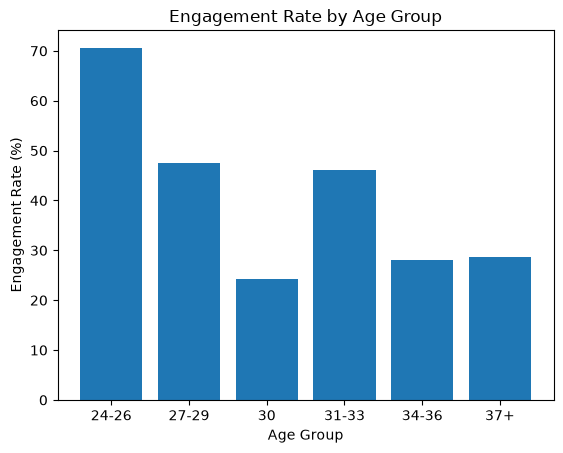

In [90]:
import matplotlib.pyplot as plt
plt.bar(
    results["age_group"].to_list(),
    results["engagement_rate"].to_list()
)
plt.xlabel("Age Group")
plt.ylabel("Engagement Rate (%)")
plt.title("Engagement Rate by Age Group")
plt.show()

<Axes: xlabel='age_group', ylabel='engagement_rate'>

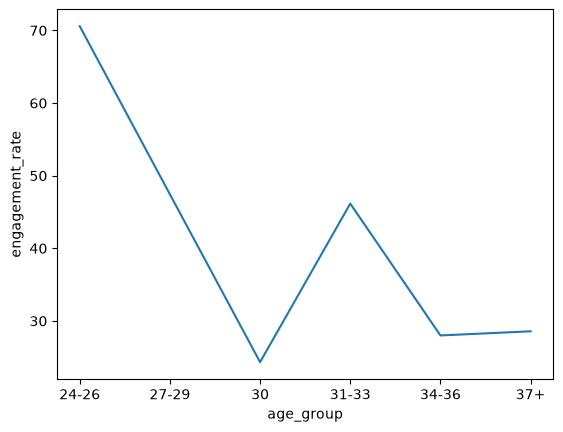

In [91]:
sns.lineplot(data=results, x="age_group", y="engagement_rate", markers=True)

In [92]:
women_contestants = contestants.filter(pl.col("gender") == 'F')
engaged_women_contestants = women_contestants.filter(pl.col("engaged") == 1)
avg_age_engaged_women_contestants = engaged_women_contestants.select(pl.mean("age").cast(pl.Int64))
youngest_engaged_women_contestants = engaged_women_contestants.select(pl.min("age"))
oldest_engaged_women_contestants = engaged_women_contestants.select(pl.max("age"))
median_engaged_women_contestants = engaged_women_contestants.select(pl.median("age"))
print("--------------Engaged Female Contestant Summary--------------------")
print("mean")
print(avg_age_engaged_women_contestants)
print("youngest contestant")
print(youngest_engaged_women_contestants)
print("oldest contestant")
print(oldest_engaged_women_contestants)
print("median")
print(median_engaged_women_contestants)
single_women_contestants = women_contestants.filter(pl.col("engaged") == 0)
avg_age_single_women_contestants = single_women_contestants.select(pl.mean('age').cast(pl.Int64))
youngest_single_women_contestants = single_women_contestants.select(pl.min("age"))
oldest_single_women_contestants = single_women_contestants.select(pl.max("age"))
median_single_women_contestants = single_women_contestants.select(pl.median("age"))
print("--------------Single Female Contestant Summary--------------------")
print("mean")
print(avg_age_single_women_contestants)
print("youngest contestant")
print(youngest_single_women_contestants)
print("oldest contestant")
print(oldest_single_women_contestants)
print("median")
print(median_single_women_contestants)


--------------Engaged Female Contestant Summary--------------------
mean
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 30  │
└─────┘
youngest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 24  │
└─────┘
oldest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 39  │
└─────┘
median
shape: (1, 1)
┌──────┐
│ age  │
│ ---  │
│ f64  │
╞══════╡
│ 31.0 │
└──────┘
--------------Single Female Contestant Summary--------------------
mean
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 31  │
└─────┘
youngest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 24  │
└─────┘
oldest contestant
shape: (1, 1)
┌─────┐
│ age │
│ --- │
│ i64 │
╞═════╡
│ 43  │
└─────┘
median
shape: (1, 1)
┌──────┐
│ age  │
│ ---  │
│ f64  │
╞══════╡
│ 31.0 │
└──────┘


<Axes: xlabel='age'>

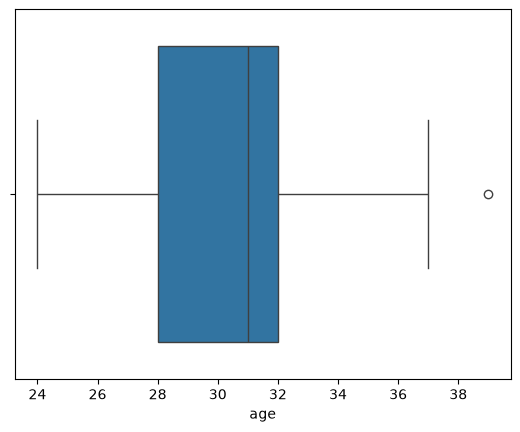

In [93]:
sns.boxplot(engaged_women_contestants, x="age")


<Axes: xlabel='age'>

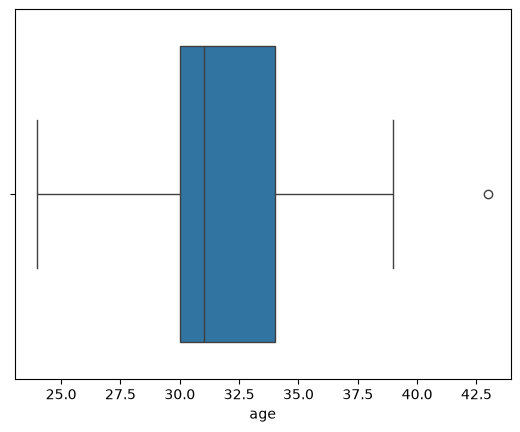

In [94]:
sns.boxplot(single_women_contestants, x="age")

<Axes: xlabel='age', ylabel='Count'>

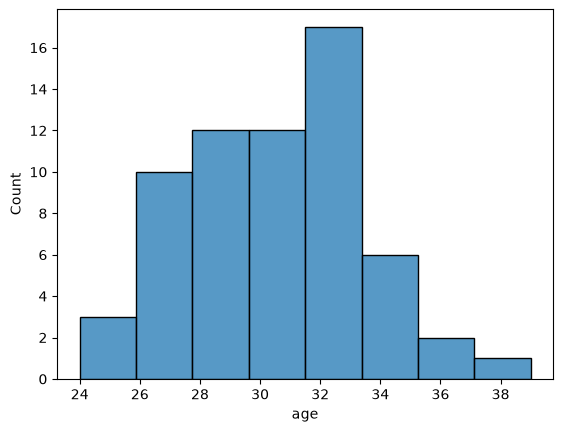

In [95]:
sns.histplot(engaged_women_contestants, x="age")

<Axes: xlabel='age', ylabel='Count'>

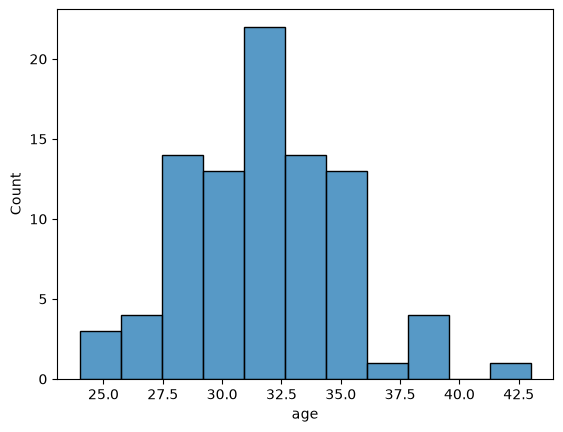

In [96]:
sns.histplot(single_women_contestants, x="age")

In [97]:
results_by_gender = (
    contestants.group_by(["gender", "age_group"])
    .agg(
        pl.len().alias("total_contestants"),
        pl.col("engaged").sum().alias("engaged_contestants "), 
        (pl.col("engaged").mean() * 100).alias("engagement_rate")
    )
    .sort(["gender", "age_group"])
)
print(results_by_gender)

shape: (12, 5)
┌────────┬───────────┬───────────────────┬──────────────────────┬─────────────────┐
│ gender ┆ age_group ┆ total_contestants ┆ engaged_contestants  ┆ engagement_rate │
│ ---    ┆ ---       ┆ ---               ┆ ---                  ┆ ---             │
│ str    ┆ str       ┆ u32               ┆ i64                  ┆ f64             │
╞════════╪═══════════╪═══════════════════╪══════════════════════╪═════════════════╡
│ F      ┆ 24-26     ┆ 11                ┆ 7                    ┆ 63.636364       │
│ F      ┆ 27-29     ┆ 35                ┆ 18                   ┆ 51.428571       │
│ F      ┆ 30        ┆ 15                ┆ 2                    ┆ 13.333333       │
│ F      ┆ 31-33     ┆ 56                ┆ 27                   ┆ 48.214286       │
│ F      ┆ 34-36     ┆ 26                ┆ 6                    ┆ 23.076923       │
│ …      ┆ …         ┆ …                 ┆ …                    ┆ …               │
│ M      ┆ 27-29     ┆ 43                ┆ 19                